# Tutorial: GION SZ maps

This notebook shows how to read the GION thermal and kinetic Sunyaev-Zel'dovich (tSZ and kSZ) maps and visualise them.

**Before running:** download both maps with [`download_sz.sh`](download_sz.sh):

```sh
sh download_sz.sh all
```

The maps are saved as `SZ_maps/GION_r000_tSZ_GNFW_nres13.fits` and `SZ_maps/GION_r000_kSZ.fits`. Each map is about 6.4 GB, and loading it needs a similar amount of memory, so we load one map at a time.

## Setup

The maps are full-sky HEALPix maps with $N_\mathrm{side} = 8192$, which we read with `healpy`.

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

## Thermal SZ map

The tSZ map gives the Compton-$y$ parameter in each pixel.

In [2]:
y = hp.read_map("SZ_maps/GION_r000_tSZ_GNFW_nres13.fits")
nside = hp.get_nside(y)
npix = hp.nside2npix(nside)
print("Nside:", nside)
print("Npix:", npix)
print(f"Mean y: {y.mean():.3e}")

Nside: 8192
Npix: 805306368
Mean y: 7.832e-07


The $y$ map is positive and dominated by a few bright clusters, so we show it on a logarithmic colour scale, $10^{-7} < y < 10^{-4}$.

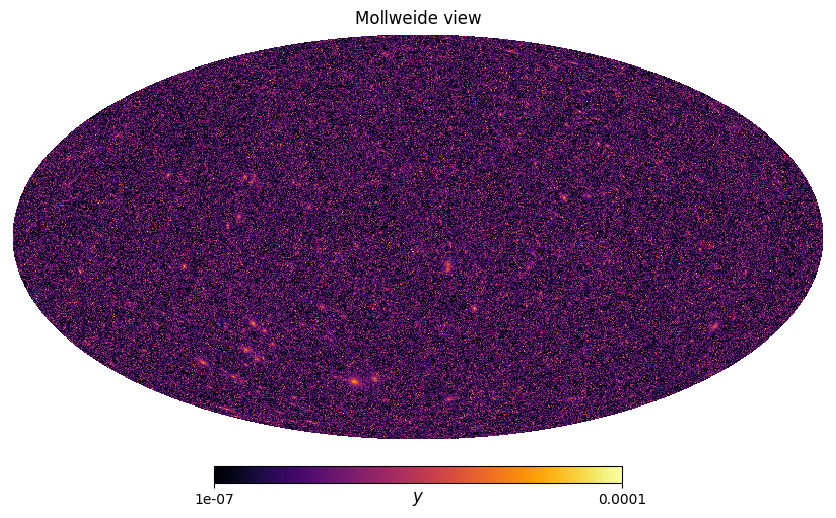

In [3]:
hp.mollview(y, unit=r"$y$", norm="log", min=1e-7, max=1e-4, cmap='inferno')
plt.show()

As for the convergence maps, let's zoom into a $5^\circ \times 5^\circ$ patch with the gnomonic projection (750 pixels of 0.4 arcmin).

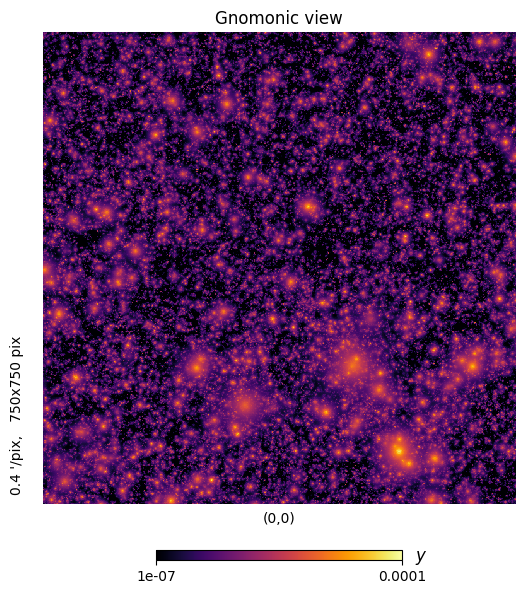

In [4]:
hp.gnomview(y, rot=(0.0, 0.0), xsize=750, reso=0.4, unit=r"$y$", norm="log", min=1e-7, max=1e-4, cmap='inferno')
plt.show()

We free the memory before loading the kSZ map.

In [5]:
del y

## Kinetic SZ map

The kSZ map gives the temperature fluctuation relative to the mean CMB temperature as Doppler-$b$ parameter.

In [6]:
b = hp.read_map("SZ_maps/GION_r000_kSZ.fits")
print(f"Mean: {b.mean():.3e}")
print(f"RMS:  {b.std():.3e}")

Mean: 1.097e-07
RMS:  1.968e-06


Unlike $y$, the kSZ signal can be positive or negative depending on whether the gas moves away from or towards us. We use a diverging colour map with the range $-5 \times 10^{-6} < b < 5 \times 10^{-6}$.

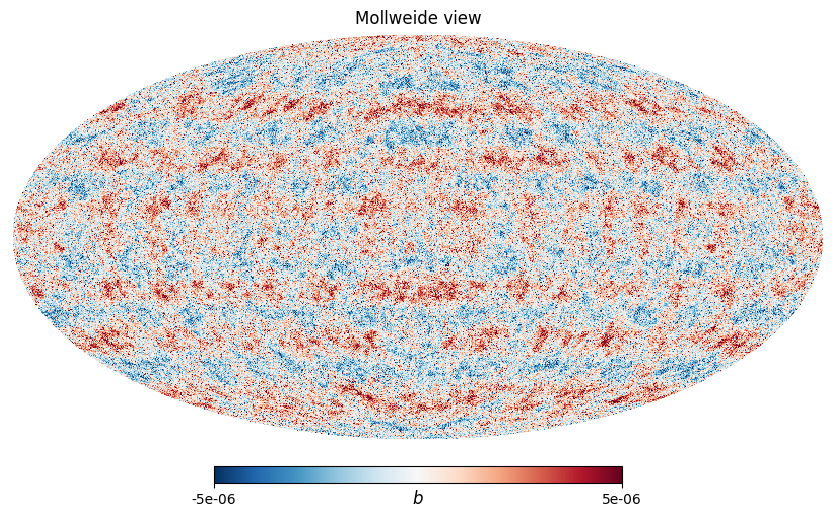

In [7]:
hp.mollview(b, unit=r"$b$", min=-5e-6, max=5e-6, cmap='RdBu_r')
plt.show()

The same $5^\circ \times 5^\circ$ patch as for the tSZ map:

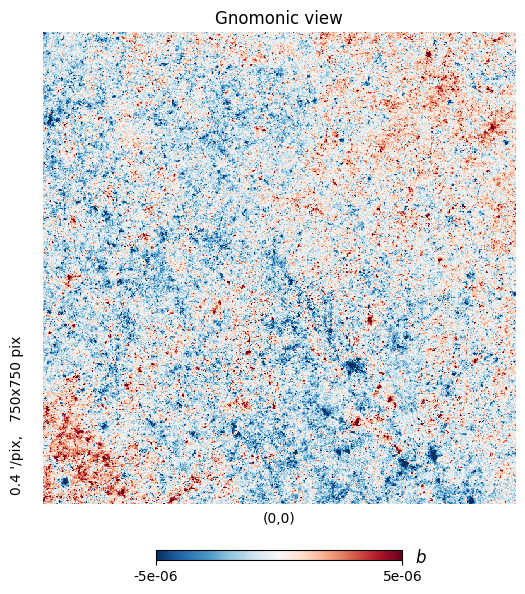

In [8]:
hp.gnomview(b, rot=(0.0, 0.0), xsize=750, reso=0.4, unit=r"$b$", min=-5e-6, max=5e-6, cmap='RdBu_r')
plt.show()

In [9]:
del b